# Citi Bike station digital twin: step by step

This notebook walks through the project: real trip data, the demand at one station, the digital twin, its validation, and the test of four rebalancing policies.

Data: Citi Bike public trip history, Jersey City and Hoboken, June 2023 (see `data/README.md`).

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('..'))
import pandas as pd
import matplotlib.pyplot as plt
from citibike_twin import load_trips, hourly_rates, daily_departures, system_summary, simulate, Policy, POLICIES, summarize

trips = load_trips('../data/JC-202306-citibike-tripdata.csv')
system_summary(trips)

{'trips': 97023,
 'days': 30,
 'stations': 144,
 'avg_trips_per_day': np.float64(3234.0),
 'member_share': np.float64(0.711),
 'classic_share': np.float64(0.855),
 'median_minutes': np.float64(6.8)}

## 1. The whole system
Trips have a morning peak around 8 am and a stronger evening peak between 5 pm and 7 pm.

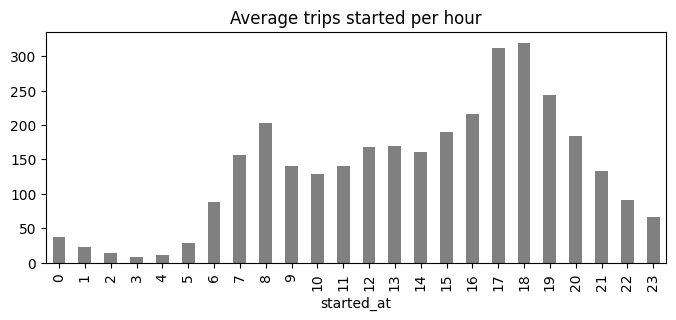

In [2]:
per_hour = trips.groupby(trips.started_at.dt.hour).size() / trips.started_at.dt.date.nunique()
per_hour.plot(kind='bar', color='grey', figsize=(8, 3), title='Average trips started per hour');

## 2. Demand at Grove St PATH, the busiest station
`hourly_rates` gives the average number of bikes taken (`dep`) and returned (`arr`) per weekday hour.

In [3]:
station = 'Grove St PATH'
rates = hourly_rates(trips, station)
rates.round(1).T

hour,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
dep,2.1,0.9,0.6,0.4,0.9,0.7,5.9,5.1,3.7,3.2,...,5.8,8.6,15.0,24.5,29.0,19.2,12.6,10.6,7.6,4.3
arr,0.9,0.4,0.4,0.1,1.5,3.1,16.0,30.9,36.5,14.4,...,5.2,7.6,8.5,10.5,12.0,8.5,7.6,4.0,3.5,1.7


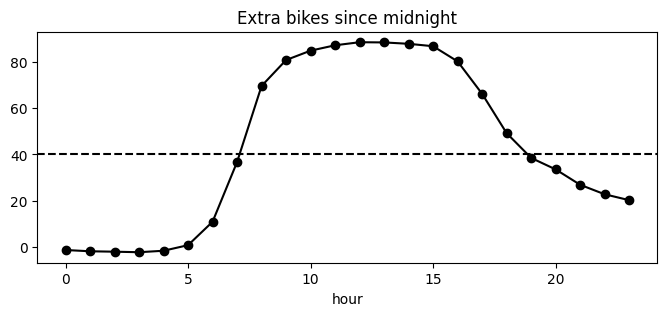

In [4]:
(rates.arr - rates.dep).cumsum().plot(marker='o', color='black', figsize=(8, 3), title='Extra bikes since midnight');
plt.axhline(40, ls='--', color='black');

## 3. Validation
The twin must reproduce real demand. With unlimited docks, the simulated bikes taken per day should match the real days.

In [5]:
observed = daily_departures(trips, station)
val, _ = simulate(rates, Policy(), capacity=10**6, n_days=300)
pd.DataFrame({'real': observed.describe(), 'twin': val.served_dep.describe()}).round(1)

,real,twin
count,22.0,300.0
mean,176.9,174.8
std,25.4,25.7
min,112.0,118.0
25%,163.0,157.8
50%,177.0,172.5
75%,194.8,192.0
max,218.0,262.0


## 4. Testing the policies (40 docks assumed)

In [6]:
rows = {}
paths = {}
for name, policy in POLICIES.items():
    days, path = simulate(rates, policy, capacity=40, n_days=200)
    rows[name] = summarize(days)
    paths[name] = path
table = pd.DataFrame(rows).T.round(1)
table

,Failed rentals/day,Failed returns/day,Riders affected/day,Minutes empty/day,Minutes full/day,Truck visits/day,Bikes moved/day,Riders nudged/day
AS IS (no intervention),33.9,73.0,106.9,161.0,254.8,0.0,0.0,0.0
A. Scheduled trucks,15.9,22.1,38.0,103.8,45.8,4.0,86.2,0.0
B. Sensor triggered trucks,2.3,10.3,12.6,5.6,20.6,7.6,134.9,0.0
C. Rider incentives only,14.6,43.1,57.7,97.6,198.7,0.0,0.0,57.1
D. Sensor trucks + incentives,0.6,3.8,4.4,1.7,10.6,7.2,120.6,22.8


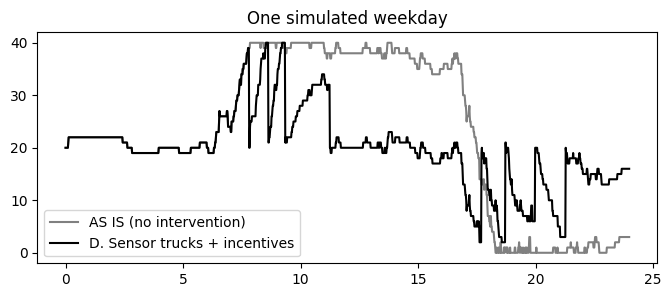

In [7]:
pd.DataFrame({k: paths[k] for k in ['AS IS (no intervention)', 'D. Sensor trucks + incentives']}).set_index(pd.Index(range(1440)) / 60).plot(figsize=(8, 3), color=['grey', 'black'], title='One simulated weekday');

## 5. Conclusion
Combining sensor triggered trucks with rider incentives (option D) cuts the number of riders affected by about 96 percent compared with no intervention, with fewer truck visits than trucks alone. The number of docks, the truck delay and the rider reaction rate are assumptions; see the README.